# ETL para SQL Server y SSIS
**Diego Salinas Laguna · AI4I 2020**

Este notebook demuestra la extracción y transformación. El procedimiento de publicación
está en `sql/sqlserver/02_carga_full.sql`. La carga SQL se ejecuta con SSIS o con
`scripts/sqlserver/Datamart.ps1`; este notebook no la publica automáticamente.

**Fechas simuladas para la práctica:** no son fechas originales de operación.

In [1]:
from pathlib import Path
import sys, hashlib, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
while not (root / 'src/etl_sqlserver.py').exists():
    if root == root.parent:
        raise FileNotFoundError('Abre Jupyter dentro de la carpeta completa del proyecto.')
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from etl_sqlserver import transformar, preparar
original = root / 'data/raw/ai4i2020.csv'
huella_inicial = hashlib.sha256(original.read_bytes()).hexdigest()
datos = pd.read_csv(original)
print('Filas y columnas originales:', datos.shape)
display(datos.head())

Filas y columnas originales: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Revisar antes de cargar
Comprobamos valores faltantes, filas repetidas y etiquetas. Las discrepancias
no se corrigen sin una justificación del origen.

In [2]:
calidad = pd.Series({
    'filas': len(datos),
    'columnas_originales': len(datos.columns),
    'valores_nulos': int(datos.isna().sum().sum()),
    'filas_duplicadas': int(datos.duplicated().sum()),
    'observaciones_con_falla': int(datos['Machine failure'].sum()),
    'discrepancias_etiquetas': int(datos['Machine failure'].ne(
        datos[['TWF','HDF','PWF','OSF','RNF']].max(axis=1)).sum()),
})
display(calidad.to_frame('valor'))
display(datos[['Air temperature [K]', 'Process temperature [K]',
               'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']].describe())

,valor
filas,10000
columnas_originales,14
valores_nulos,0
filas_duplicadas,0
observaciones_con_falla,339
discrepancias_etiquetas,27


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


## 2. Transformar y agregar fechas
`transformar` valida nombres, tipos, identificadores y rangos. Renombra columnas,
ordena por UDI y agrega claves de tipo y tiempo.

La fecha es `2026-01-01 + floor((UDI - 1) / 50)` días.
Repetir la carga conserva las mismas fechas. `tiempo_id` usa AAAAMMDD.

In [3]:
procesados = transformar(datos)
display(procesados.loc[[0,49,50,99,9999],
    ['udi','product_id','tipo','tipo_id','fecha_operacion_simulada','tiempo_id']])
print('Desde:', procesados.fecha_operacion_simulada.min())
print('Hasta:', procesados.fecha_operacion_simulada.max())
print('Días con datos:', procesados.tiempo_id.nunique())
assert procesados.groupby('tiempo_id').size().eq(50).all()
assert transformar(datos.sample(frac=1, random_state=42)).equals(procesados)

,udi,product_id,tipo,tipo_id,fecha_operacion_simulada,tiempo_id
0,1,M14860,M,2,2026-01-01,20260101
49,50,M14909,M,2,2026-01-01,20260101
50,51,L47230,L,1,2026-01-02,20260102
99,100,L47279,L,1,2026-01-02,20260102
9999,10000,M24859,M,2,2026-07-19,20260719


Desde: 2026-01-01
Hasta: 2026-07-19
Días con datos: 200


## 3. Visualizar el calendario de práctica
Las barras muestran el reparto de registros entre meses simulados. Julio es parcial.
La diferencia se debe a la regla de asignación, no a cambios reales de producción.

,observaciones,fallas,porcentaje_fallas
mes,,,
2026-01,1550,43,2.774194
2026-02,1400,31,2.214286
2026-03,1550,103,6.645161
2026-04,1500,78,5.200000
2026-05,1550,32,2.064516
2026-06,1500,34,2.266667
2026-07,950,18,1.894737


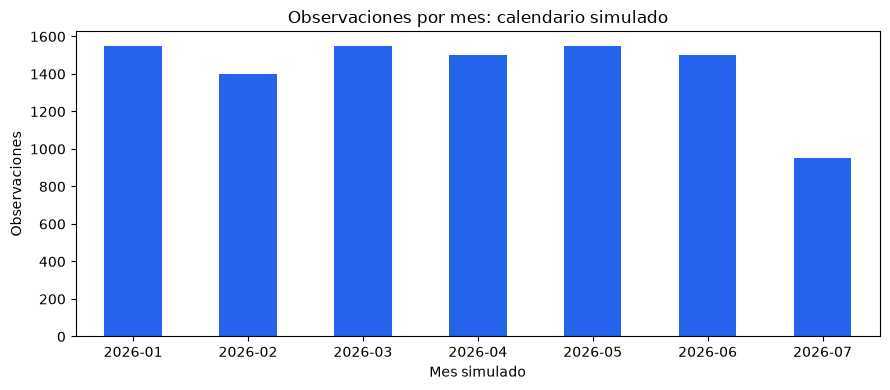

In [4]:
mensual = procesados.assign(mes=procesados.fecha_operacion_simulada.str[:7])
resumen = mensual.groupby('mes').agg(observaciones=('udi','size'), fallas=('estado_id','sum'))
resumen['porcentaje_fallas'] = resumen.fallas / resumen.observaciones * 100
display(resumen)
ax = resumen.observaciones.plot.bar(color='#2563eb', figsize=(9,4), rot=0)
ax.set(title='Observaciones por mes: calendario simulado', xlabel='Mes simulado', ylabel='Observaciones')
plt.tight_layout()
plt.show()

## 4. Preparar una ejecución independiente
`preparar` crea una carpeta por ejecución con CSV, staging, discrepancias y manifiesto.
Preparar archivos no acredita una carga SQL. SHA-256 comprueba que el original no cambió.

In [5]:
ejecucion = preparar(root)
manifiesto = json.loads((ejecucion / 'manifiesto.json').read_text(encoding='utf-8'))
display(pd.Series(manifiesto).to_frame('valor'))
print('Archivos preparados:', sorted(p.name for p in ejecucion.iterdir()))
assert hashlib.sha256(original.read_bytes()).hexdigest() == huella_inicial
print('Original conservado sin cambios.')

,valor
carga_id,7b163387-7a6c-4864-8503-ec36bb050928
filas,10000
sha256_original,dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1...
sha256_staging,f91fc296c43cbc53d86eb5584da3cdbec3235e03da5f77...
fecha_preparacion_utc,2026-11-20T08:48:52.383894+00:00
fecha_inicial_simulada,2026-01-01
fecha_final_simulada,2026-07-19
discrepancias_etiquetas,27
regla,2026-01-01 + floor((UDI - 1) / 50) días
tipo_carga,FULL


Archivos preparados: ['ai4i_procesado.csv', 'discrepancias.csv', 'manifiesto.json', 'staging.csv']
Original conservado sin cambios.


## 5. Publicar mediante SSIS y comprobar el Data Mart
Seguir `docs/INSTALACION_SQLSERVER_SSIS_POWERBI.md` para configurar el servidor y
generar el paquete. Sus cinco tareas preparan objetos, transforman CSV, cargan
staging, publican FULL y verifican.

`dm.fact_operacion` guarda 10,000 observaciones. `dm.dim_tipo`, `dm.dim_estado`
y `dm.dim_tiempo` permiten filtrar por tipo, estado y fecha. Hay 365 días en
calendario y 200 utilizados en hechos. El historial de cargas no se elimina.

La publicación SQL valida antes de borrar y usa una transacción con rollback.
La segunda ejecución reemplaza las filas y mantiene el total de 10,000.

En Power BI abrir `powerbi/Mantenimiento.pbip`, actualizar y mostrar la vista Modelo.
La fecha real de carga se almacena aparte, en UTC.

In [6]:
verificacion = root / 'results/sqlserver/ultima_verificacion.json'
if verificacion.exists():
    evidencia = json.loads(verificacion.read_text(encoding='utf-8-sig'))
    print('Evidencia histórica: comprobar servidor, fecha e identificador antes de presentarla.')
    display(pd.Series(evidencia).to_frame('valor'))
else:
    print('Pendiente: ejecución y verificación reales de SQL Server/SSIS.')

Pendiente: ejecución y verificación reales de SQL Server/SSIS.


## 6. Conexión con los modelos
**Regresión:** estimar torque con tipo, temperaturas, velocidad y desgaste.
**Clasificación:** estimar Machine failure con tipo y las cinco mediciones.
**Agrupamiento:** formar perfiles con las cinco mediciones estandarizadas.

Fechas simuladas, identificadores e indicadores específicos de falla quedan fuera
de las entradas. Los notebooks previos conservan entrenamiento y evaluación;
esta migración no los reentrena.